# Delaware PFAS results and charts

This report reads the tables from the SQL analysis to present the PWS results, compound detection frequencies, sample point hazard indices, and an approximate zipcode map.

In [42]:
from pathlib import Path
from getpass import getpass
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, URL

# Saved chart directory
FIGURE_DIR = Path("reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

## 1. Connect to the database and check the analysis tables

In [ ]:
DB_USER = ""
DB_NAME = "pfas_analysis"
DB_HOST = "localhost"
DB_PORT = 5432

connection_details = URL.create(
    "postgresql+psycopg", username=DB_USER, password=getpass("PostgreSQL password: "),
    host=DB_HOST, port=DB_PORT, database=DB_NAME
)
engine = create_engine(connection_details)
del connection_details

In [101]:
# Make sure there are no missing tables
# If something is missing, make sure to run the loader and SQL files 01 to 04.
check_query = """
SELECT current_database() AS database_name,
       to_regclass('public.results')::text AS results_view,
       to_regclass('public.pws_levels')::text AS PWS_table,
       to_regclass('public.samplepoint_hi')::text AS hi_table,
       to_regclass('public.hi_events')::text AS hi_event_table,
       to_regclass('public.zipcodes')::text AS zipcode_table;
"""
connection_check = pd.read_sql_query(check_query, engine)
connection_check

,database_name,results_view,pws_table,hi_table,hi_event_table,zipcode_table
0,pfas_analysis,results,pws_levels,None,hi_events,None


## 2. Check the included data

In [44]:
# Check the number of rows and PWS
overview_query = """
SELECT COUNT(*) AS row_count,
       COUNT(DISTINCT pwsid) AS pws_count
FROM public.results;
"""
source_overview = pd.read_sql_query(overview_query, engine)
source_overview

,row_count,pws_count
0,1925327,10312


In [47]:
# Get Delaware PWS data
delaware_query = """
SELECT pwsid, pwsname, size, max_ratio, compounds_above_limit, status, level
FROM public.pws_levels
WHERE state = 'DE'
ORDER BY max_ratio DESC, pwsname;
"""
delaware_pws = pd.read_sql_query(delaware_query, engine)
delaware_pws.head()

,pwsid,pwsname,size,max_ratio,compounds_above_limit,status,level
0,DE0000630,"NEWARK WATER DEPARTMENT, DE",L,5.6625,2,Above limit,Level 3: well above limit
1,DE0000552,ARTESIAN WATER COMPANY,L,5.5625,2,Above limit,Level 3: well above limit
2,DE0000564,SUEZ WATER DELAWARE,L,4.8250,1,Above limit,Level 3: well above limit
3,DE0000592,GEORGETOWN WATER DEPARTMENT,S,4.5000,3,Above limit,Level 3: well above limit
4,DE0000723,REHOBOTH BEACH WATER DEPARTMENT,L,2.6375,1,Above limit,Level 3: well above limit


## 3. How many Delaware PWS fall into each status and priority level?
Each PWS takes its most serious result from all the compounds and sample points:

- **Above limit:** At least one compound's average is above its limit, even when nondetects count as zero
- **Possible:** Nondetects make it uncertain whether an average concentration is above its limit
- **Below limit:** All averages are below or at their limits, even when nondetects count at their reporting limits

For priority, **Level 3** means at least 2x a compound's limit, **Level 2** means above a limit but less than twice the amount, and **Level 1** means Possible. The hazard index is shown separately and doesn't affect these classifications.

In [39]:
# Set the chart order and colors
status_order = ["Below limit", "Possible", "Above limit"]
status_colors = {"Below limit": "lightgray", "Possible": "gold", "Above limit": "salmon"}
level_order = ["Below or at limits", "Level 1: resample", "Level 2: above limit", "Level 3: well above limit"]
level_colors = {"Below or at limits": "lightgray", "Level 1: resample": "gold", "Level 2: above limit": "orange", "Level 3: well above limit": "salmon"}

status_counts = delaware_pws["status"].value_counts().reindex(status_order, fill_value=0)
level_counts = delaware_pws["level"].value_counts().reindex(level_order, fill_value=0) #< in case there are 0 PWS in a category
status_counts, level_counts

(status
 Below limit    22
 Possible        2
 Above limit    12
 Name: count, dtype: int64,
 level
 Below or at limits           22
 Level 1: resample             2
 Level 2: above limit          4
 Level 3: well above limit     8
 Name: count, dtype: int64)

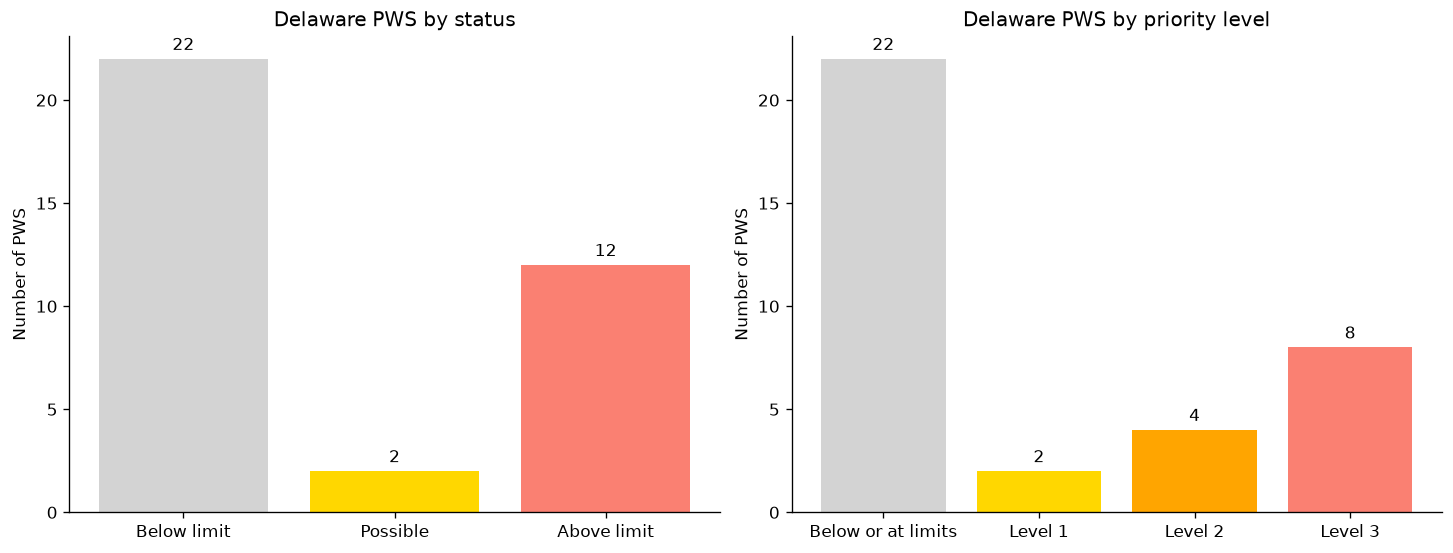

In [93]:
# Show the charts side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
axes[0].bar(status_counts.index, status_counts.values, color=status_counts.index.map(status_colors))
axes[0].set_title("Delaware PWS by status")
axes[0].set_ylabel("Number of PWS")
axes[0].bar_label(axes[0].containers[0], padding=3)

axes[1].bar(["Below or at limits", "Level 1", "Level 2", "Level 3"], level_counts.values, color=level_counts.index.map(level_colors))
axes[1].set_title("Delaware PWS by priority level")
axes[1].set_ylabel("Number of PWS")
axes[1].bar_label(axes[1].containers[0], padding=3)

fig.savefig(FIGURE_DIR / "pws_status_and_levels.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. How far above the limit are the results?
Each bar shows the largest multiple of a compound's limit found for that PWS, using its average at a sample point.  
For example, an average of 8 ppt compared with a limit of 4 ppt gives a bar of 2.  
The dashed line at 1 represents the limit.

Nondetects count as zero in these averages. Therefore, a PWS classified as Possible can have a bar below 1.  
Counting its nondetects at their reporting limits could put the compound's average above a limit.  

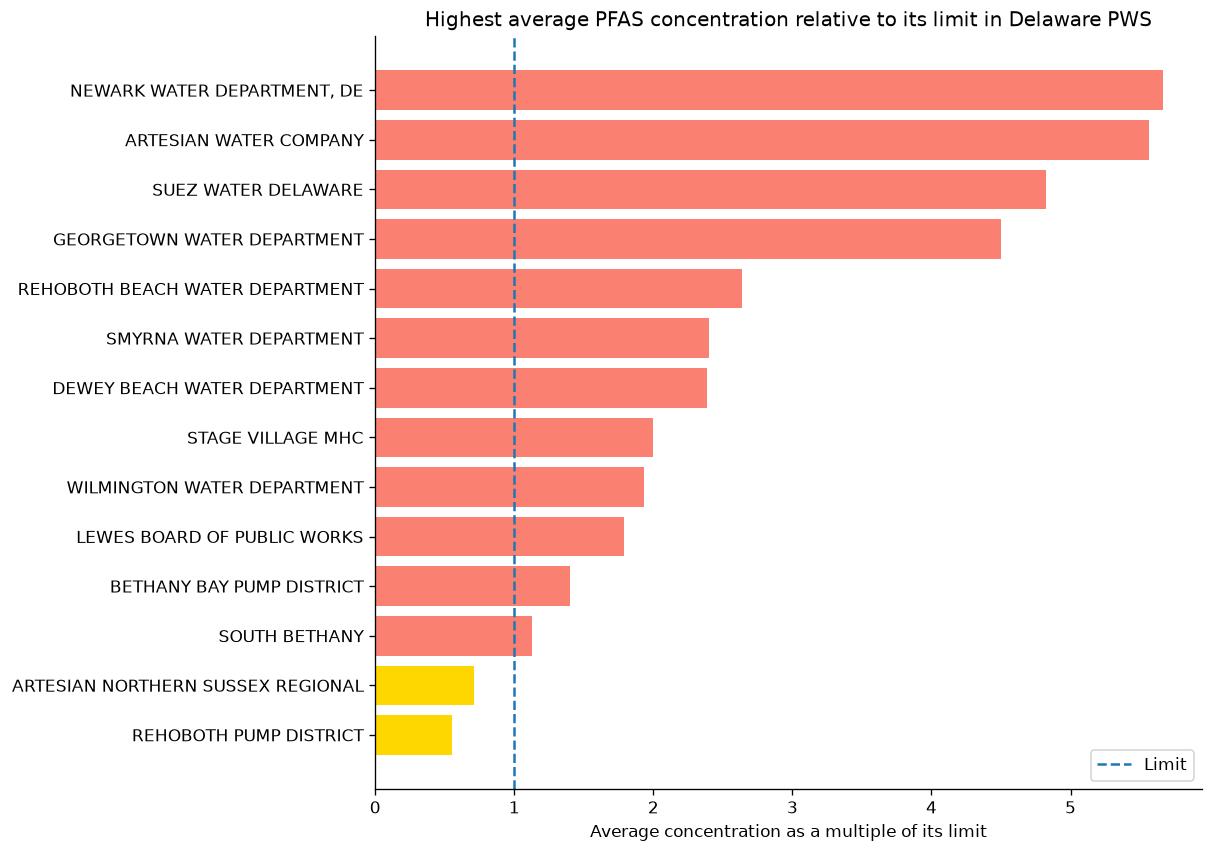

In [96]:
# Only look at PWS that are Above limit and Possible
ratio_plot = delaware_pws[delaware_pws["status"] != "Below limit"]
ratio_plot = ratio_plot.sort_values("max_ratio") # Sort

fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.barh(ratio_plot["pwsname"], ratio_plot["max_ratio"], color=ratio_plot["status"].map(status_colors))
ax.axvline(1, linestyle="--", label="Limit")
ax.set_title("Highest average PFAS concentration relative to its limit in Delaware PWS")
ax.set_xlabel("Average concentration as a multiple of its limit")
ax.legend()
fig.savefig(FIGURE_DIR / "pws_concentration_limit.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Which compounds are detected most often in Delaware?
For each compound, count Delaware PWS that had at least one detection and divide by the number of Delaware PWS that tested for that compound.  
The chart shows the 12 highest detection percentages. It includes PFAS without individual limits.

In [102]:
# For each PWS, find whether it detected each compound at least once
detection_query = """
SELECT pwsid, contaminant, MAX(detected) AS any_detect
FROM public.results
WHERE state = 'DE'
GROUP BY pwsid, contaminant;
"""
pws_detections = pd.read_sql_query(detection_query, engine)

# Calculate the percentage of PWS with a detection for each compound.
detection_frequency = (pws_detections.groupby("contaminant")["any_detect"].mean().mul(100)
    .sort_values(ascending=False).reset_index(name="pct_detected"))

detection_frequency

,contaminant,pct_detected
0,PFPeA,38.888889
1,PFHxA,36.111111
2,PFOA,33.333333
3,PFBS,30.555556
4,PFOS,25.000000
5,PFBA,19.444444
6,PFHxS,16.666667
7,PFHpA,16.666667
8,PFNA,5.555556
9,8:2 FTS,2.777778


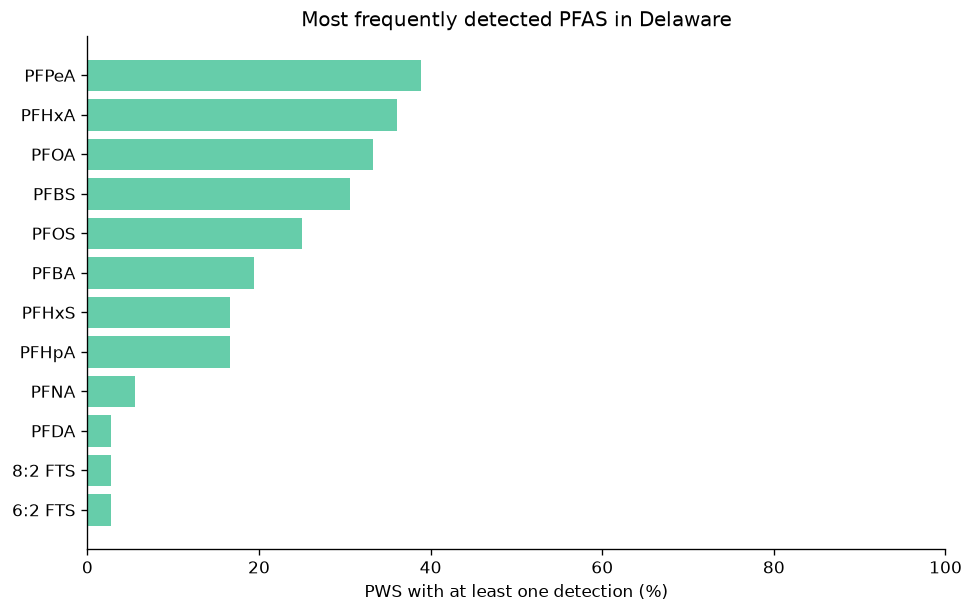

In [97]:
# Plot the 12 highest detection percentages
compound_plot = detection_frequency.head(12)
compound_plot = compound_plot.sort_values("pct_detected")

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.barh(range(len(compound_plot)), compound_plot["pct_detected"], color="mediumaquamarine")
ax.set_yticks(range(len(compound_plot)), labels=compound_plot["contaminant"])
ax.set_xlim(0, 100)
ax.set_xlabel("PWS with at least one detection (%)")
ax.set_title("Most frequently detected PFAS in Delaware")
fig.savefig(FIGURE_DIR / "compound_frequency.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. How does Delaware compare nationally?
Compare the percentage of included PWS classified as Above limit.  
The chart shows the 15 highest percentages among states and territories with at least 10 included PWS. Then 10 PWS cutoff avoids very small groups.

In [68]:
# Calculate the national count and percentage of PWS Above limit
national_query = """
SELECT COUNT(*) AS pws,
       SUM(CASE WHEN status = 'Above limit' THEN 1 ELSE 0 END) AS above_limit,
       100.0 * SUM(CASE WHEN status = 'Above limit' THEN 1 ELSE 0 END) / NULLIF(COUNT(*), 0) AS pct_above_limit
FROM public.pws_levels;
"""
national_summary = pd.read_sql_query(national_query, engine)
national_summary

,pws,above_limit,pct_above_limit
0,10307,1194,11.58436


In [71]:
# Calculate the same values for each state or territory with at least 10 PWS
state_query = """
SELECT state,
       COUNT(*) AS pws,
       SUM(CASE WHEN status = 'Above limit' THEN 1 ELSE 0 END) AS above_limit,
       100.0 * SUM(CASE WHEN status = 'Above limit' THEN 1 ELSE 0 END) / COUNT(*) AS pct_above_limit
FROM public.pws_levels
GROUP BY state
HAVING COUNT(*) >= 10
ORDER BY pct_above_limit DESC, state;
"""
state_summary = pd.read_sql_query(state_query, engine)
state_summary.head()

,state,pws,above_limit,pct_above_limit
0,CT,63,29,46.031746
1,NJ,265,120,45.283019
2,SC,165,57,34.545455
3,DE,36,12,33.333333
4,FL,408,132,32.352941


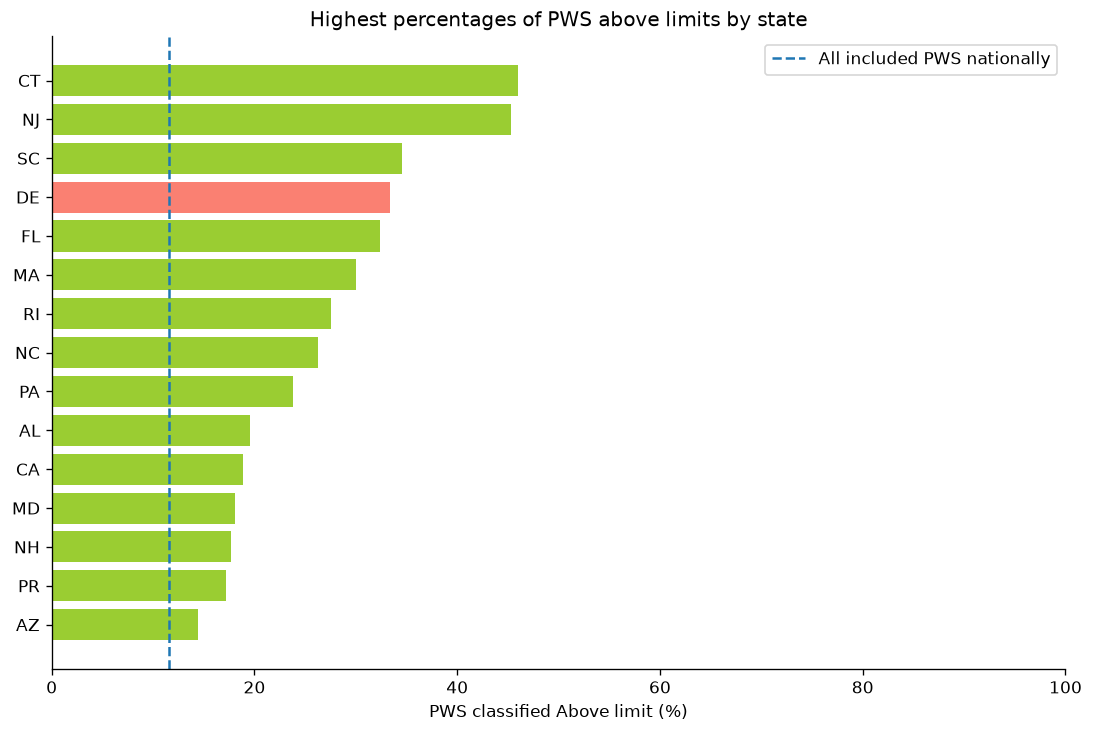

In [100]:
state_plot = state_summary.head(15)
state_plot = state_plot.sort_values("pct_above_limit").copy()
state_plot["color"] = "yellowgreen"
state_plot.loc[state_plot["state"] == "DE", "color"] = "salmon" 
# ^ highlight Delaware among the 15 highest observed percentages
national_percentage = national_summary.loc[0, "pct_above_limit"]

fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
ax.barh(state_plot["state"], state_plot["pct_above_limit"], color=state_plot["color"])
ax.axvline(national_percentage, linestyle="--", label="All included PWS nationally")
ax.set_xlim(0, 100)
ax.set_xlabel("PWS classified Above limit (%)")
ax.set_title("Highest percentages of PWS above limits by state")
ax.legend()
fig.savefig(FIGURE_DIR / "state_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Which sample points have the highest hazard index?
The hazard index adds the contributions of PFHxS, PFNA, HFPO-DA, and PFBS within each sampling event. 
The chart below shows the ten sample points with the highest hazard index averages in Delaware.

Only events with all 4 compounds reported are used in the average. Nondetects stay included and contribute 0.  
Due to nondetects contributing as 0, an index at or below 1 doesn't mean that the true index is at or below 1. 

In [78]:
# Count events that are incomplete or contain a repeated compound
hi_query_check = """
SELECT i.state,
       COUNT(*) AS events,
       SUM(CASE
           WHEN h.compounds_reported = 4 THEN 0 ELSE 1 END) AS excluded_events
FROM public.hi_events h
JOIN public.pws_info i ON h.pwsid = i.pwsid
GROUP BY i.state
ORDER BY i.state;
"""
hi_audit = pd.read_sql_query(hi_query_check, engine)
hi_audit[hi_audit["state"] == "DE"]

,state,events,excluded_events
18,DE,269,0


In [79]:
# Read the sample point averages from SQL
hi_query = """
SELECT i.pwsname, h.pwsid, h.facilityid, h.samplepointid, h.hazard_index
FROM public.samplepoint_hi h
JOIN public.pws_info i ON h.pwsid = i.pwsid
WHERE i.state = 'DE'
ORDER BY h.hazard_index DESC, i.pwsname, h.samplepointid;
"""
delaware_hi = pd.read_sql_query(hi_query, engine)
delaware_hi.head(10)

DatabaseError: Execution failed on sql '
SELECT i.pwsname, h.pwsid, h.facilityid, h.samplepointid, h.hazard_index
FROM public.samplepoint_hi h
JOIN public.pws_info i ON h.pwsid = i.pwsid
WHERE i.state = 'DE'
ORDER BY h.hazard_index DESC, i.pwsname, h.samplepointid;
': (psycopg.errors.UndefinedTable) relation "public.samplepoint_hi" does not exist
LINE 3: FROM public.samplepoint_hi h
             ^
[SQL: 
SELECT i.pwsname, h.pwsid, h.facilityid, h.samplepointid, h.hazard_index
FROM public.samplepoint_hi h
JOIN public.pws_info i ON h.pwsid = i.pwsid
WHERE i.state = 'DE'
ORDER BY h.hazard_index DESC, i.pwsname, h.samplepointid;
]
(Background on this error at: https://sqlalche.me/e/21/f405)

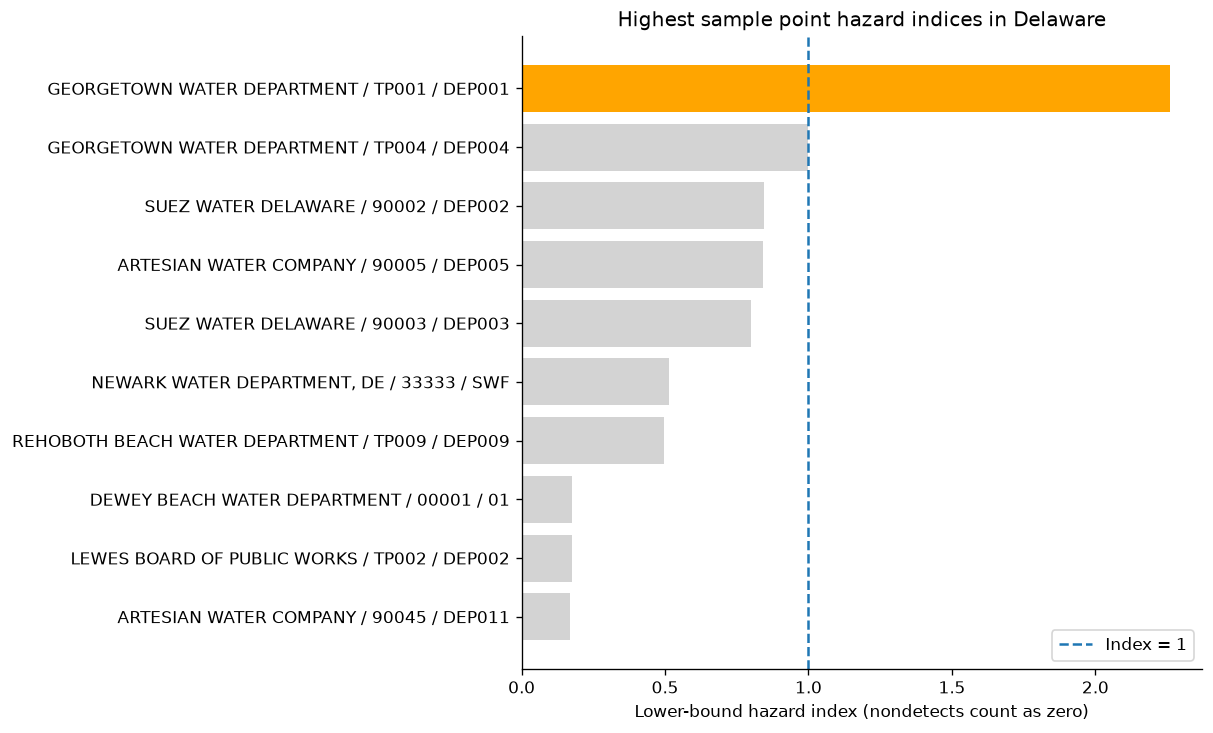

In [ ]:
# Show the ten highest sample point averages
hi_plot = delaware_hi.head(10)
hi_plot = hi_plot.sort_values("hazard_index").copy()
hi_plot["samplepoint_label"] = hi_plot["pwsname"] + " / " + hi_plot["facilityid"].fillna("unknown") + " / " + hi_plot["samplepointid"]
hi_plot["color"] = "lightgray"
hi_plot.loc[hi_plot["hazard_index"] > 1, "color"] = "orange"

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
ax.barh(hi_plot["samplepoint_label"], hi_plot["hazard_index"], color=hi_plot["color"])
ax.axvline(1, linestyle="--", label="Index = 1")
ax.set_title("Highest sample point hazard indices in Delaware")
ax.set_xlabel("Lower-bound hazard index (nondetects count as zero)")
ax.legend()
fig.savefig(FIGURE_DIR/"highest_hazard_index.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Zipcode priority map
Each zipcode takes the highest priority level among its Delaware PWS. So, one Level 3 PWS would make the zipcode Level 3.  
PWS zipcode links are approximate - they do not show exact service boundaries.

In [ ]:
# Find each zipcode's highest associated level and count its PWS
zipcode_query = """
SELECT z.zipcode,
       MAX(CASE l.level
           WHEN 'Level 3: well above limit' THEN 3
           WHEN 'Level 2: above limit' THEN 2
           WHEN 'Level 1: resample' THEN 1
           WHEN 'Below or at limits' THEN 0 END) AS worst_rank,
       COUNT(DISTINCT l.pwsid) AS all_pws_count,
       COUNT(DISTINCT CASE WHEN l.status = 'Above limit' THEN l.pwsid END) AS above_limit_pws_count
FROM public.zipcodes z
JOIN public.pws_levels l ON z.pwsid = l.pwsid
WHERE l.state = 'DE'
GROUP BY z.zipcode
ORDER BY z.zipcode;
"""
zipcode_summary = pd.read_sql_query(zipcode_query, engine)
rank_level = {0: "Below or at limits", 1: "Level 1: resample", 2: "Level 2: above limit", 3: "Level 3: well above limit"}
zipcode_summary["worst_level"] = zipcode_summary["worst_rank"].map(rank_level)
zipcode_summary

,zipcode,worst_rank,all_pws_count,above_limit_pws_count,worst_level
0,19082,2,1,1,Level 2: above limit
1,19701,3,3,3,Level 3: well above limit
2,19702,3,3,3,Level 3: well above limit
3,19703,3,1,1,Level 3: well above limit
4,19707,3,2,2,Level 3: well above limit
5,19708,2,1,1,Level 2: above limit
6,19709,0,3,0,Below or at limits
7,19710,2,1,1,Level 2: above limit
8,19711,3,3,3,Level 3: well above limit
9,19713,3,2,2,Level 3: well above limit


In [ ]:
# Match the zipcode summary to the Census map areas
SHAPEFILE = Path("data/raw/tl_2020_us_zcta520.shp")
map_data = None

import geopandas as gpd
zcta = gpd.read_file(SHAPEFILE)
map_data = zcta.merge(zipcode_summary, left_on="ZCTA5CE20", right_on="zipcode", how="inner")
map_data = map_data.to_crs(epsg=4326)
map_data["geometry"] = map_data.geometry.simplify(0.001, preserve_topology=True)
map_data = map_data[["zipcode", "worst_level", "all_pws_count", "above_limit_pws_count", "geometry"]]

In [ ]:
# Choose each zipcode area's fill color using its priority level
def zipcode_style(feature):
    level = feature["properties"]["worst_level"]
    return {"fillColor": level_colors[level], "color": "gray", "weight": 0.5, "fillOpacity": 0.7}

if map_data is not None:
    import folium
    zipcode_map = folium.Map(location=[39.0, -75.5], zoom_start=8, tiles="OpenStreetMap")
    folium.GeoJson(
        map_data,
        style_function=zipcode_style,
        tooltip=folium.GeoJsonTooltip(
            fields=["zipcode", "worst_level", "all_pws_count", "above_limit_pws_count"],
            aliases=["Zipcode:", "Highest associated level:", "Associated PWS:", "PWS above a limit:"]
        )
    ).add_to(zipcode_map)


In [ ]:
# Add the legend and save the interactive map
if map_data is not None:
    legend_html = """<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:12px;border:1px solid #999;">
    <b>Highest associated priority level</b><br>
    <span style="color:salmon">■</span> Level 3: well above limit<br>
    <span style="color:orange">■</span> Level 2: above limit<br>
    <span style="color:gold">■</span> Level 1: resample<br>
    <span style="color:lightgray">■</span> Below or at limits<br>
    <small>Approximate zipcode associations, not service boundaries.</small></div>"""
    zipcode_map.get_root().html.add_child(folium.Element(legend_html))
    zipcode_map.save("reports/delaware_zipcode_priority.html")
    zipcode_map

In [ ]:
# Close the database connection
engine.dispose()